# Phân loại Bình luận Spam / Ham trên Mạng Xã hội FB

Thử nghiệm pipeline phân loại bình luận (comments) tiếng Việt thành 2 nhóm:
* **Ham**: Bình luận bình thường, thảo luận hợp lệ của người dùng.
* **Spam**: Bình luận rác, chèo kéo bán hàng, quảng cáo, cờ bạc, lừa đảo hoặc chứa liên kết độc hại.

Pipeline thực nghiệm gồm các bước:
1. **Khám phá và phân tích dữ liệu (EDA)**
2. **Tiền xử lý văn bản chuyên biệt (Data Preprocessing)**
3. **Trích xuất đặc trưng & Biểu diễn vector (Feature Engineering)**
4. **Huấn luyện mô hình học máy (Model Training)**
5. **Đánh giá mô hình (Model Evaluation)**

## Thiết lập Môi trường và Thư viện


In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from underthesea import word_tokenize
from gensim.models import Word2Vec
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer    
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from scipy.sparse import hstack

pd.set_option('display.max_colwidth', None) # Show full text 

/home/peterjohn/miniconda3/envs/ai_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Khám phá Dữ liệu (Exploratory Data Analysis - EDA)


### Đọc tập dữ liệu tự gán nhãn

In [2]:
df = pd.read_csv('auto_labeled_comments.csv')

Accuracy: 0.919
              precision    recall  f1-score   support

         ham     0.9519    0.9552    0.9535       870
        spam     0.6929    0.6769    0.6848       130

    accuracy                         0.9190      1000
   macro avg     0.8224    0.8160    0.8192      1000
weighted avg     0.9182    0.9190    0.9186      1000



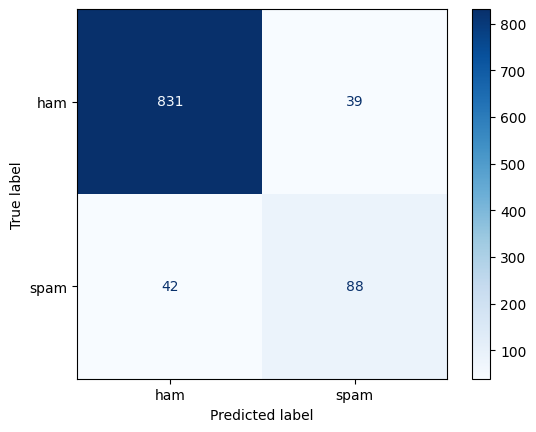

In [3]:
manual = pd.read_csv('merged_manual_comments.csv')
y_true, y_pred = manual['label'], df['label'].iloc[:1000]
print('Accuracy:', accuracy_score(y_true, y_pred))
print(classification_report(y_true, y_pred, digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=['ham', 'spam'], cmap='Blues')
plt.show()


In [ ]:
# llm = df.iloc[:1000].copy()

# reviewed = manual.copy()
# for i in manual.index[manual['label'] != llm['label']]:
#     print(f"\n[{i}] {manual.at[i, 'content']}\nThủ công: {manual.at[i, 'label']} | LLM: {llm.at[i, 'label']}")
#     label = input('Chốt nhãn (ham/spam): ').strip().lower()
#     while label not in ('ham', 'spam'):
#         label = input('Nhập ham hoặc spam: ').strip().lower()
#     reviewed.at[i, 'label'] = label
# reviewed.to_csv('reviewed_comments.csv', index=False, encoding='utf-8-sig')
# df = reviewed.copy()



[5] @nêu bật à tui còn có cả cuốn Kinh tế lượng nữa ạ. Các bé vô quẹo lựa nha
Thủ công: spam | LLM: ham

[53] Học đúng trọng tâm – bám sát đề thi thật – cập nhật liên tục, không lan man, không học thừa
Thủ công: ham | LLM: spam

[54] Lộ trình rõ ràng, có chiến lược từng kỹ năng
Thủ công: ham | LLM: spam

[88] mình nhận nhé, lấy 15k thôi
Thủ công: ham | LLM: spam

[95] qua chỗ Ao Sen tìm đi e :))) Có dán sđt đấy
Thủ công: spam | LLM: ham

[104] ib tớ
Thủ công: ham | LLM: spam

[105] ib
Thủ công: ham | LLM: spam

[161] theo giá in ở Ao sen + 5k=))
Thủ công: spam | LLM: ham

[238] "Everytime bạn nha "
Thủ công: spam | LLM: ham

[280] 6. em ạ, a từng quy đổi IELTS r này em có thắc mắc về quy đổi có thể ib anh nhé
Thủ công: spam | LLM: ham

[282] Uy tín 100%
Thủ công: spam | LLM: ham

[293] bạn pass được chưa ạ, chưa pass dc ib zalo mình nha 0968041255
Thủ công: ham | LLM: spam

[325] Nếu b đang tìm trọ thì ib mk
Thủ công: ham | LLM: spam

[329] Mình ké với ạ, B nào ghép nhóm học vstep bên

- Đưa vào báo cáo, bao nhiêu % mẫu LLM bị nhận xét sai =, chênh lệch bao nhiêu phần trăm

In [5]:
df = pd.read_csv('reviewed_comments.csv')

### Kiểm tra kích thước và kiểu dữ liệu
1. **Dataset Shape**: Số lượng hàng (mẫu) và số lượng cột (thuộc tính).
2. **Non-Null Count**: Kiểm tra giá trị khuyết thiếu (missing values) trên các trường dữ liệu.

In [6]:
print('Dataset Shape:', df.shape)
df.info()

Dataset Shape: (1000, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  1000 non-null   object
 1   label    1000 non-null   object
dtypes: object(2)
memory usage: 15.8+ KB


### Xem một số mẫu dữ liệu ngẫu nhiên

In [7]:
df.head(10)

,content,label
0,"k chăm chỉ là đc e, lên là các thầy cho vào ngay",ham
1,Phan Bảo Hai Anh neu m biet m se biet,ham
2,Tôi có,ham
3,giỏi,ham
4,Xứt sắc,ham
5,@nêu bật à tui còn có cả cuốn Kinh tế lượng nữa ạ. Các bé vô quẹo lựa nha,spam
6,Cho pass vs,ham
7,Tadv dễ hơn em ạ,ham
8,Có cả chống gian lận trên lms cơ à=))) PTIT đầu tư ác thế,ham
9,Tẹt ga,ham


### Khảo sát các mẫu bình luận Spam thực tế

In [8]:
df[df["label"]=="spam"].head(5)

,content,label
5,@nêu bật à tui còn có cả cuốn Kinh tế lượng nữa ạ. Các bé vô quẹo lựa nha,spam
18,b đưa sđt đây,spam
19,Hỗ Trợ Làm ED ib page này nhanh nhất nhé,spam
22,Dạ bạn thi ở 281 Khuất Duy Tiến i.b mình hỗ trợ nhé. Bạn có thể check trang FB của mình cho yên tâm ạ,spam
30,cô Kim Dung aptis,spam


### Thống kê phân bố nhãn (Class Distribution)
* Khảo sát tỷ lệ giữa nhãn `ham` và `spam` để xác định mức độ chênh lệch nhãn của bài toán.

In [9]:
df['label'].value_counts()

label
ham     860
spam    140
Name: count, dtype: int64

### Trực quan hóa phân bố nhãn bằng biểu đồ cột

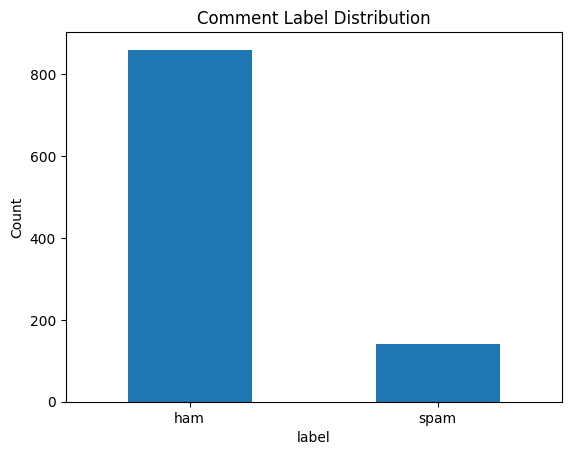

In [10]:
df['label'].value_counts().plot(kind='bar', rot=0)
plt.title('Comment Label Distribution')
plt.ylabel('Count')
plt.show()

### Phân tích độ dài ký tự của bình luận theo nhãn
* **Boxplot**: So sánh phân vị, trung vị và các giá trị ngoại lai (outliers) về độ dài ký tự giữa bình luận bình thường và bình luận spam.

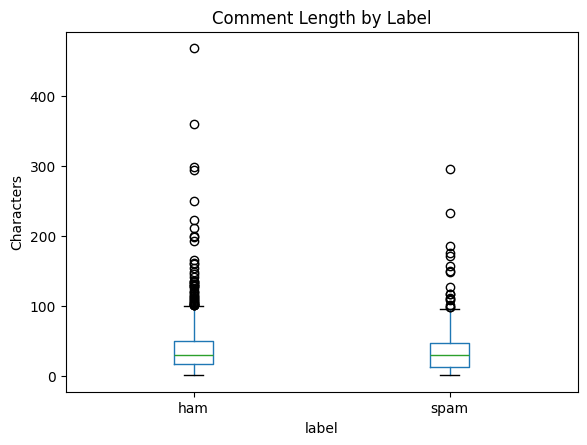

In [11]:
df['char_len'] = df['content'].astype(str).str.len()
df.boxplot(column='char_len', by='label', grid=False)
plt.title('Comment Length by Label')
plt.suptitle('')
plt.ylabel('Characters')
plt.show()

## 2. Tiền Xử Lý Dữ Liệu (Data Preprocessing)
  1. **Chuyển chữ thường (Lowercasing)**: Đồng nhất chữ hoa, chữ thường.
  2. **Tokenization chuyên biệt**: Quy đổi đường link (`token_url`), số điện thoại (`token_sdt`), và từ khóa liên hệ/mời gọi (`token_lienhe` như ib, zalo, sđt) thành các Token đặc trưng đại diện.
  3. **Lọc ký tự đặc biệt**: Giữ lại ký tự chữ và số.
  4. **Tách từ tiếng Việt**: Sử dụng công cụ `underthesea` để ghép các từ ghép (VD: "bán_hàng", "liên_hệ").
  5. **Loại bỏ Stopwords**: Lọc bỏ các từ dừng - từ có tần số cao nhưng ít mang giá trị phân biệt ngữ nghĩa.

### Định nghĩa hàm tiền xử lý văn bản

In [12]:
STOPWORDS = {'là', 'thì', 'và', 'của', 'những', 'các', 'một', 'được', 'với', 'ở', 'này', 'đó', 'cho'}

def preprocess(text):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' token_url ', text)
    text = re.sub(r'(?:(?:\+|00)?84|0)(?:\d[\s\.]?){8,10}\d', ' token_sdt ', text)
    text = re.sub(r'\b(i[\.\s]?b|inbox|inb|zalo|zl|lh|liên hệ)\b', ' token_lienhe ', text)
    text = re.sub(r'[^\w\s]', ' ', text)
    tokens = word_tokenize(text, format='text').split()
    return ' '.join(w for w in tokens if w not in STOPWORDS)

### Áp dụng tiền xử lý lên toàn bộ tập dữ liệu

In [13]:
df['processed'] = df['content'].apply(preprocess)
df[['content', 'processed', 'label']].head(10)

,content,processed,label
0,"k chăm chỉ là đc e, lên là các thầy cho vào ngay",k chăm_chỉ đc e lên thầy vào ngay,ham
1,Phan Bảo Hai Anh neu m biet m se biet,phan_bảo hai anh neu m biet m se biet,ham
2,Tôi có,tôi có,ham
3,giỏi,giỏi,ham
4,Xứt sắc,xứt sắc,ham
5,@nêu bật à tui còn có cả cuốn Kinh tế lượng nữa ạ. Các bé vô quẹo lựa nha,nêu bật à tui còn có cả cuốn kinh_tế lượng nữa ạ bé vô_quẹo lựa nha,spam
6,Cho pass vs,pass vs,ham
7,Tadv dễ hơn em ạ,tadv dễ hơn em ạ,ham
8,Có cả chống gian lận trên lms cơ à=))) PTIT đầu tư ác thế,có cả chống gian_lận trên lms cơ à ptit đầu_tư ác_thế,ham
9,Tẹt ga,tẹt ga,ham


### Phân Chia Tập Dữ Liệu (Train / Test Split)
1. **Tỷ lệ phân chia**: 80% tập huấn luyện (Train) và 20% tập kiểm thử (Test).
2. **Stratified Sampling (`stratify=df['label']`)**: Bảo toàn tỷ lệ phân bố giữa nhãn ham và spam tương đồng trên cả 2 tập, tránh bias khi đánh giá trên tập dữ liệu mất cân bằng.

In [14]:
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=42, stratify=df['label'])
train = df.loc[train_idx].copy()
test = df.loc[test_idx].copy()
pd.DataFrame({'Train': train['label'].value_counts(), 'Test': test['label'].value_counts()})

,Train,Test
label,,
ham,688,172
spam,112,28


## 3. Trích Xuất Đặc Trưng & Biểu Diễn Vector (Feature Engineering)
* Nghiên cứu so sánh 4 không gian biểu diễn đặc trưng văn bản khác nhau:
  1. **Bag of Words (BoW)**: Biểu diễn tần số xuất hiện từ và cụm từ (1-gram, 2-gram).
  2. **TF-IDF**: Trọng số hóa tần số từ theo nghịch đảo tần số văn bản.
  3. **Word2Vec Averaging**: Biểu diễn ngữ nghĩa phân tán (dense semantic embedding) bằng trung bình cộng vector từ.
  4. **Word2Vec TF-IDF Weighted**: Trung bình có trọng số IDF nhằm ưu tiên các từ mang tính đặc thù cao hơn.
  5. **Hybrid (TF-IDF + Word2Vec)**: Kết hợp vector n-gram thưa và vector ngữ nghĩa đặc bằng phép ghép nối (concatenation/hstack).

### Mô hình Bag-of-Words (BoW / N-gram Count)
* Cấu hình: `ngram_range=(1, 2)` (kết hợp cả unigram và bigram), loại bỏ các từ chỉ xuất hiện 1 lần (`min_df=2`).

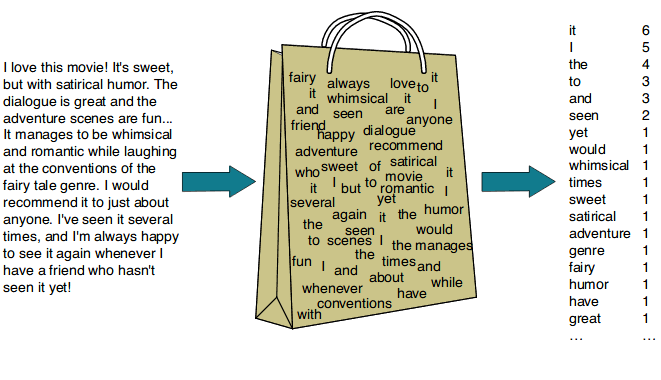

In [15]:
vec_bow = CountVectorizer(ngram_range=(1, 2), min_df=2)
X_train_bow = vec_bow.fit_transform(train['processed'])
X_test_bow = vec_bow.transform(test['processed'])
print('BoW Vocabulary Size:', X_train_bow.shape[1])

BoW Vocabulary Size: 1021


### Khảo sát danh sách đặc trưng BoW

In [16]:
feature_names = vec_bow.get_feature_names_out()
print("100 đặc trưng đầu:")
print(feature_names[:100])
print("\n100 đặc trưng cuối:")
print(feature_names[-100:])

100 đặc trưng đầu:
['10' '100' '14' '14 tín' '15' '18' '19' '2006' '2026' '22' '225' '29'
 '30' '500' '730' '730 toeic' 'a2' 'ac' 'ac có' 'ae' 'ai' 'ak' 'andiez'
 'anh' 'anh còn' 'anh nhé' 'anh_chị' 'ao' 'ao sen' 'ao_sen' 'app' 'app gì'
 'apply' 'aptis' 'art' 'attt' 'auto' 'b1' 'b2' 'bao_nhiêu' 'bcs' 'biết'
 'biết cách' 'bn' 'bnh' 'bomber' 'bomber size' 'bro' 'bt' 'buổi' 'bà'
 'bài' 'bài báo_cáo' 'bài mà' 'bài_tập' 'bác' 'bán' 'bán đâu' 'báo'
 'báo_cáo' 'bây_giờ' 'bé' 'bên' 'bình' 'bù' 'bạn' 'bạn bị' 'bạn có'
 'bạn có_thể' 'bạn mình' 'bạn nhé' 'bạn nào' 'bạn nữ' 'bạn pass' 'bạn vào'
 'bạn ơi' 'bạn_đọc' 'bảo' 'bắt' 'bắt_buộc' 'bắt_đầu' 'bắt_đầu từ' 'bằng'
 'bị' 'bị mất' 'bọn' 'bọn mình' 'bỏ' 'bổ_trợ' 'bộ' 'bờ' 'bục' 'bừa'
 'cam_kết' 'cam_kết đầu_ra' 'cao' 'cbi' 'ch' 'check' 'check qldt']

100 đặc trưng cuối:
['ít' 'ôi' 'ôn' 'ôn_tadv' 'ông' 'ăn' 'đam_mê' 'đang' 'đang tìm' 'đc'
 'đc ko' 'đc miễn_là' 'đc đâu' 'đem' 'đi' 'đi có' 'đi học' 'đi không'
 'đi thi' 'điều_kiện' 'điểm' 'điểm cao' 'đ

### Trích xuất mẫu vector BoW của 1 bình luận

In [17]:
print("Raw:", train.iloc[36]["content"])
print("Processed:", train.iloc[36]["processed"])
print("Vector BoW:", X_train_bow[36].toarray())
np.savetxt("out/vector_bow.txt", X_train_bow[36].toarray().ravel(), fmt="%.6f")
print("Shape:", X_train_bow[36].shape)

Raw: Em với ạ
Processed: em ạ
Vector BoW: [[0 0 0 ... 0 0 0]]
Shape: (1, 1021)


### Mô hình TF-IDF (Term Frequency - Inverse Document Frequency)
* Cấu hình: `ngram_range=(1, 2)`, `min_df=2`, bật `sublinear_tf=True` (thay thế $tf$ bằng $1 + \log(tf)$) giúp làm dịu ảnh hưởng của các từ lặp lại nhiều lần.

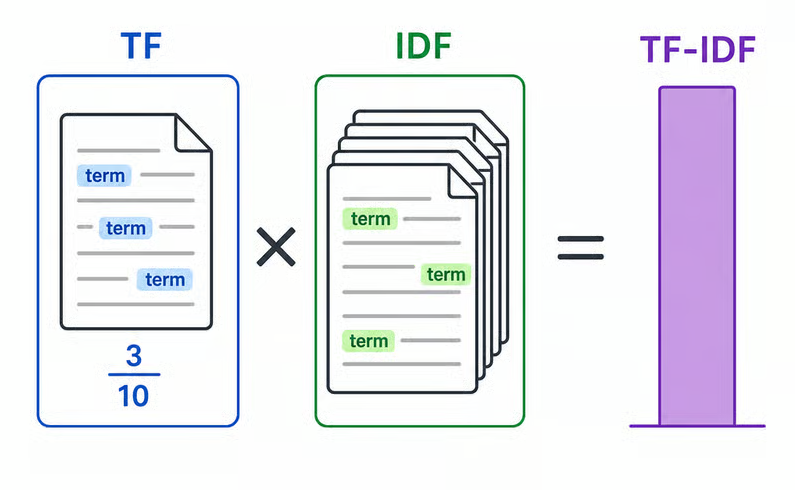

In [18]:
vec_tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_tfidf = vec_tfidf.fit_transform(train['processed'])
X_test_tfidf = vec_tfidf.transform(test['processed'])
print('TF-IDF Features Size:', X_train_tfidf.shape[1])

TF-IDF Features Size: 1021


### Khảo sát danh sách đặc trưng TF-IDF

In [19]:
feature_names = vec_tfidf.get_feature_names_out()
print("100 đặc trưng đầu:", feature_names[:100])
print("100 đặc trưng cuối:", feature_names[-100:])

100 đặc trưng đầu: ['10' '100' '14' '14 tín' '15' '18' '19' '2006' '2026' '22' '225' '29'
 '30' '500' '730' '730 toeic' 'a2' 'ac' 'ac có' 'ae' 'ai' 'ak' 'andiez'
 'anh' 'anh còn' 'anh nhé' 'anh_chị' 'ao' 'ao sen' 'ao_sen' 'app' 'app gì'
 'apply' 'aptis' 'art' 'attt' 'auto' 'b1' 'b2' 'bao_nhiêu' 'bcs' 'biết'
 'biết cách' 'bn' 'bnh' 'bomber' 'bomber size' 'bro' 'bt' 'buổi' 'bà'
 'bài' 'bài báo_cáo' 'bài mà' 'bài_tập' 'bác' 'bán' 'bán đâu' 'báo'
 'báo_cáo' 'bây_giờ' 'bé' 'bên' 'bình' 'bù' 'bạn' 'bạn bị' 'bạn có'
 'bạn có_thể' 'bạn mình' 'bạn nhé' 'bạn nào' 'bạn nữ' 'bạn pass' 'bạn vào'
 'bạn ơi' 'bạn_đọc' 'bảo' 'bắt' 'bắt_buộc' 'bắt_đầu' 'bắt_đầu từ' 'bằng'
 'bị' 'bị mất' 'bọn' 'bọn mình' 'bỏ' 'bổ_trợ' 'bộ' 'bờ' 'bục' 'bừa'
 'cam_kết' 'cam_kết đầu_ra' 'cao' 'cbi' 'ch' 'check' 'check qldt']
100 đặc trưng cuối: ['ít' 'ôi' 'ôn' 'ôn_tadv' 'ông' 'ăn' 'đam_mê' 'đang' 'đang tìm' 'đc'
 'đc ko' 'đc miễn_là' 'đc đâu' 'đem' 'đi' 'đi có' 'đi học' 'đi không'
 'đi thi' 'điều_kiện' 'điểm' 'điểm cao' 'đi

### Trích xuất mẫu vector TF-IDF của 1 bình luận

In [20]:
print("Raw:", train.iloc[36]["content"])
print("Processed:", train.iloc[36]["processed"])
print("Vector TF-IDF:", X_train_tfidf[36].toarray())
np.savetxt("out/vector_tfidf.txt", X_train_tfidf[36].toarray().ravel(), fmt="%.6f")
print("Shape:", X_train_tfidf[36].shape)

Raw: Em với ạ
Processed: em ạ
Vector TF-IDF: [[0. 0. 0. ... 0. 0. 0.]]
Shape: (1, 1021)


### Huấn luyện mô hình nhúng từ Word2Vec (Continuous Skip-gram / CBOW)
1. **vector_size=100**: Kích thước chiều không gian embedding của mỗi từ.
2. **window=5**: Kích thước cửa sổ ngữ cảnh xung quanh từ mục tiêu.
3. **epochs=50**: Số lượt duyệt qua tập ngữ liệu train.

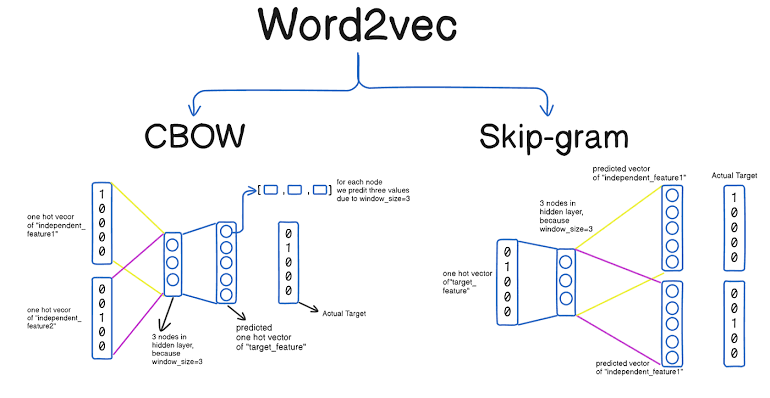

In [21]:
sentences = [s.split() for s in train['processed']]
w2v_model = Word2Vec(sentences, vector_size=100, window=5, min_count=1, workers=1, epochs=50, seed=42)
print('Word2Vec Vocabulary Size:', len(w2v_model.wv))

Word2Vec Vocabulary Size: 1664


### Khảo sát từ vựng đã học trong mô hình Word2Vec

In [22]:
print("100 từ đầu:", w2v_model.wv.index_to_key[:100])
print("100 từ cuối:", w2v_model.wv.index_to_key[-100:])

100 từ đầu: ['có', 'mình', 'ạ', 'em', 'k', 'nhé', 'học', 'b', 'bạn', 'token_lienhe', '1', 'e', 'không', 'mà', 'đc', 'ko', 'còn', 'ơi', 'cần', 'đi', 'vào', 'thôi', 'đâu', 'thi', 'trường', 'để', 'nào', '2', 'năm', 'mới', 'cũng', 'nha', 'xin', 'gì', 'rồi', 'anh', 'người', 'lại', 'mua', 'hỏi', 'điểm', 'pass', 'làm', 'ấy', 'môn', 'r', 'qua', 'nghe', 'tìm', 'vậy', 'tham_gia', 'phải', 'ra', '4', 'cái', 'đến', 'lấy', 'luôn', 'xem', 'clb', 'chỉ', 'chưa', 'token_sdt', 'trên', 'đấy', 'thế', 'nên', 'mấy', 'chị', 'hay', 'lên', 'cứ', 'toeic', 'nhưng', 'c', 'trong', 'sao', 'đang', 'hết', 'ptit', 'như', 'muốn', 'thấy', 't', 'đã', 'sẽ', 'à', '3', 'nhiều', 'xong', 'v', 'tháng', 'sau', 'ai', 'lớp', 'ẩn_danh', 'a', 'nam', 'sinh_viên', 'chứ']
100 từ cuối: ['ok_nha', 'nhưng_mà', 'thực_tập', 'kthuc', 'e_đẳng_cấp', 'giảm_giá', 'hiền_nhung', 'vstep', 'đuổi', 'fitness', 'rise', 'né', 'generation', 'nhất_định', 'hứng_thú', 'thôi_á', 'quanh_năm', 'cộng_tác_viên', 'như_thế_nào', 'bảng', 'lười_học', 'cơ_thể', 'ngôn

### Minh họa vector embedding của 1 từ cụ thể

In [23]:
word = w2v_model.wv.index_to_key[36]
print("Từ:", word)
print("Vector:", w2v_model.wv[word])
print("Shape:", w2v_model.wv[word].shape)


Từ: người
Vector: [ 0.37544107 -0.5691217  -0.578985    0.17831106 -0.4358177   0.20353703
  0.21849868  0.4240779   0.20753194  0.3413383  -0.8544107   0.0698238
  0.12106882  0.59893507  0.09368865  0.18970402 -0.2119119  -0.98706937
  0.20819078  0.02675789  0.1538546   0.17728202  0.2863809   0.75520116
  0.60083747  0.16544865 -0.24142067 -0.17189243 -0.14089145 -0.35424736
  0.07132464 -0.13367184 -0.14280331  0.07174895 -0.17969313 -0.18709308
  0.8548667  -0.97074884  0.3152052   0.4761668  -0.14472258  0.31189921
  0.8096564  -0.14411704  0.6685704  -0.13626276  0.41094428  0.29988906
  1.3466249  -0.22209187 -0.24100015 -1.7898142   0.03118452  0.11059019
  0.30681238  0.32172504  0.12428358  0.56707937 -0.11618564  0.57028764
  0.01210459 -0.09587646 -0.14176117  0.907506    0.64532685  0.588766
  0.23142974 -0.770515   -0.805404    0.44886324  0.23005234  0.03376596
 -0.5670402  -0.31283394  0.2097579  -0.1024157  -0.1694111  -0.5116659
 -0.28321502  0.00853469 -0.04507415 

### Biểu diễn bình luận bằng trung bình cộng vector từ (Word2Vec Average Pooling)
* Vector đại diện của cả bình luận được tính bằng:
  $$\mathbf{d}_{avg} = \frac{1}{|V_d|} \sum_{w \in V_d} \mathbf{v}_w$$

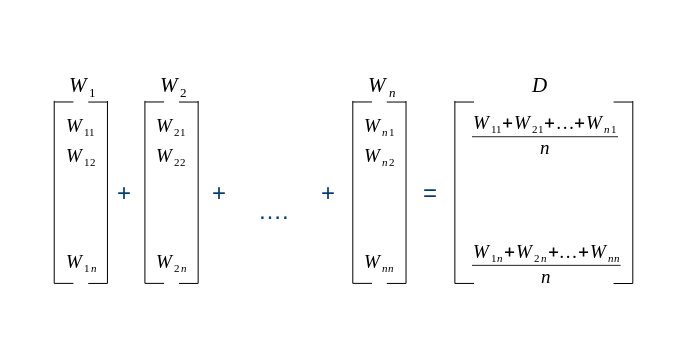

In [24]:
def doc_vector_avg(tokens):
    vecs = [w2v_model.wv[w] for w in tokens if w in w2v_model.wv]
    return np.mean(vecs, axis=0) if len(vecs) > 0 else np.zeros(w2v_model.vector_size)

X_train_w2v_avg = np.array([doc_vector_avg(s.split()) for s in train['processed']])
X_test_w2v_avg = np.array([doc_vector_avg(s.split()) for s in test['processed']])

### Trích xuất mẫu vector Word2Vec Average

In [25]:
print("Processed:", train.iloc[36]["processed"])
print("Vector Word2Vec Avg:", X_train_w2v_avg[36])
print("Shape:", X_train_w2v_avg[36].shape)
np.savetxt("out/vector_w2v_avg.txt", X_train_w2v_avg[36], fmt="%.6f")

Processed: em ạ
Vector Word2Vec Avg: [ 0.11973779 -0.072468   -0.39197928  0.01944375 -0.33594894  0.15310565
  0.28971627  0.32935339 -0.38767016  0.02631079 -0.75044394  0.30582666
  0.04504272  0.72917718 -0.31282365 -0.42800528  0.16464199 -0.54805708
 -0.38042116 -0.1060825  -0.02080522  0.29330492  0.08368738  0.48516506
  0.15583642 -0.03007371 -0.52878654  0.23129557 -0.25964326 -0.35243478
 -0.11334483 -0.17534229  0.15932886  0.11716518  0.10749383  0.05948371
  0.31849045 -0.67704976  0.06975504  0.37084734  0.13002512  0.07129066
  0.64444995 -0.2338194   0.05031016  0.15507878  0.32902443  0.27309248
  0.60985178 -0.3282156  -0.23995875 -0.99856663  0.02155773  0.04284983
  0.3208493   0.09561547 -0.23977542  0.21170683 -0.16410325  0.49998266
 -0.12906553 -0.06167698 -0.41746217  0.15974799  0.36579528  0.19879064
  0.29311222 -0.38355505 -0.3566097   0.03134824 -0.20335472  0.03204465
  0.00151775 -0.2110251   0.29684067 -0.23075756  0.12635757 -0.09807388
 -0.04829796 -

### Biểu diễn bình luận bằng Word2Vec có trọng số TF-IDF (IDF-Weighted Pooling)
* Trọng số hóa IDF nhằm gán mức độ quan trọng cao hơn cho các từ khóa mang tính phân biệt:
  $$\mathbf{d}_{weighted} = \frac{\sum_{w \in V_d} idf(w) \cdot \mathbf{v}_w}{\sum_{w \in V_d} idf(w)}$$

In [26]:
tfidf_uni = TfidfVectorizer(ngram_range=(1, 1), min_df=1)
tfidf_uni.fit(train['processed'])
idf_dict = dict(zip(tfidf_uni.get_feature_names_out(), tfidf_uni.idf_))

def doc_vector_tfidf_avg(tokens):
    vecs, weights = [], []
    for w in tokens:
        if w in w2v_model.wv:
            weight = idf_dict.get(w, 1.0)
            vecs.append(w2v_model.wv[w] * weight)
            weights.append(weight)
    return np.sum(vecs, axis=0) / sum(weights) if (len(vecs) > 0 and sum(weights) > 0) else np.zeros(w2v_model.vector_size)

X_train_w2v_tfidf = np.array([doc_vector_tfidf_avg(s.split()) for s in train['processed']])
X_test_w2v_tfidf = np.array([doc_vector_tfidf_avg(s.split()) for s in test['processed']])


### Minh họa trọng số IDF của các từ trong một bình luận mẫu

In [27]:
for w in train.iloc[36]["processed"].split():
    if w in w2v_model.wv:
        print(f"{w}: {idf_dict.get(w, 1.0):.4f}")

em: 3.1111
ạ: 1.0000


### Trích xuất mẫu vector Word2Vec có trọng số IDF

In [28]:
print("Vector Word2Vec có trọng số:", X_train_w2v_tfidf[36])
print("Shape:", X_train_w2v_tfidf[36].shape)
np.savetxt("out/vector_w2v_weighted.txt", X_train_w2v_tfidf[36], fmt="%.6f")

Vector Word2Vec có trọng số: [ 0.13865163 -0.06758595 -0.39592062  0.03776193 -0.32491298  0.14484588
  0.29731684  0.32577532 -0.38571443  0.01673604 -0.75999982  0.30239498
  0.03593613  0.72837173 -0.33885929 -0.44879563  0.18464383 -0.53238029
 -0.36915596 -0.11631113 -0.02749567  0.29556637  0.07492381  0.50922872
  0.14772053 -0.03510351 -0.54653022  0.22692165 -0.27174343 -0.36625677
 -0.11537865 -0.18603966  0.15892971  0.12710372  0.09886026  0.05834884
  0.32373204 -0.69457096  0.074252    0.37867291  0.13162112  0.07485106
  0.67612022 -0.24176788  0.05108789  0.1691138   0.33079544  0.29040682
  0.60979708 -0.33042164 -0.259441   -1.021823    0.0270219   0.05945676
  0.34593305  0.10727547 -0.2565868   0.22582291 -0.17602949  0.50239374
 -0.13151367 -0.05361317 -0.42016446  0.15227575  0.35787419  0.19849383
  0.29399438 -0.37540049 -0.36941913  0.03839511 -0.1948312   0.0500203
  0.00748972 -0.22724189  0.30634869 -0.25194985  0.14094734 -0.1018156
 -0.05498175 -0.14898715

### Không gian đặc trưng kết hợp Hybrid (TF-IDF + Word2Vec)
* Ghép nối (concatenate) vector thưa TF-IDF n-gram và vector đặc Word2Vec thành vector đa góc nhìn:
  $$\mathbf{X}_{hybrid} = [\mathbf{X}_{TF-IDF} \,\|\, \mathbf{X}_{W2V\_TFIDF}]$$

In [29]:
X_train_combined = hstack([X_train_tfidf, X_train_w2v_tfidf]).tocsr()
X_test_combined = hstack([X_test_tfidf, X_test_w2v_tfidf]).tocsr()
print('Hybrid Features Size:', X_train_combined.shape[1])

Hybrid Features Size: 1121


## 4. Huấn Luyện Mô Hình (Model Training)
* Khởi tạo các thuật toán học máy phân loại văn bản:
  1. **MultinomialNB (Multinomial Naive Bayes)**: Phù hợp với đặc trưng tần số đếm rời rạc (BoW, TF-IDF).
  <br>
  <img src="https://databasecamp.de/wp-content/uploads/naive-bayes-overview-1024x709.png" width="400" />
  
  2. **LinearSVC (Linear Support Vector Classifier)**: Tối ưu cho không gian đặc trưng nhiều chiều, sử dụng tham số `class_weight='balanced'` để tự động điều chỉnh trọng số bù đắp hiện tượng mất cân bằng lớp (data imbalance).
  <br>
  <img src="https://machinelearningcoban.com/assets/19_svm/svm3.png" width="400" />

In [30]:
multinomialNB = MultinomialNB()
linearSVC = LinearSVC(
    dual='auto', class_weight='balanced',
    C=1.0, max_iter=3000, random_state=42
)

### Huấn luyện đa mô hình trên các không gian đặc trưng
* Thực hiện huấn luyện song song các tổ hợp giữa phương pháp biểu diễn (BoW, TF-IDF, Word2Vec Avg, Word2Vec Weighted, Hybrid) và thuật toán phân loại.

In [31]:
experiments = {
    ('BoW', 'MultinomialNB'): (X_train_bow, X_test_bow, multinomialNB),
    ('BoW', 'LinearSVC'): (X_train_bow, X_test_bow, linearSVC),
    ('TF-IDF', 'MultinomialNB'): (X_train_tfidf, X_test_tfidf, multinomialNB),
    ('TF-IDF', 'LinearSVC'): (X_train_tfidf, X_test_tfidf, linearSVC),
    ('Word2Vec Avg', 'LinearSVC'): (X_train_w2v_avg, X_test_w2v_avg, linearSVC),
    ('Word2Vec TF-IDF Avg', 'LinearSVC'): (X_train_w2v_tfidf, X_test_w2v_tfidf, linearSVC),
    ('TF-IDF + Word2Vec', 'LinearSVC'): (X_train_combined, X_test_combined, linearSVC)
}

results = []
predictions = {}

for (feat, algo), (X_tr, X_te, clf) in experiments.items():
    clf.fit(X_tr, train['label'])
    y_pred = clf.predict(X_te)
    predictions[(feat, algo)] = y_pred

    results.append({
        'Feature': feat,
        'Model': algo,
        'Accuracy': accuracy_score(test['label'], y_pred),
        'Precision macro': precision_score(test['label'], y_pred, average='macro', zero_division=0),
        'Recall macro': recall_score(test['label'], y_pred, average='macro', zero_division=0),
        'Precision spam': precision_score(test['label'], y_pred, pos_label='spam', zero_division=0),
        'Recall spam': recall_score(test['label'], y_pred, pos_label='spam', zero_division=0),
        'F1 spam': f1_score(test['label'], y_pred, pos_label='spam', zero_division=0),
        'Macro F1': f1_score(test['label'], y_pred, average='macro', zero_division=0),
    })

## 5. Đánh Giá Mô Hình (Model Evaluation)

### Bảng tổng hợp so sánh kết quả thực nghiệm (Benchmark Results)
* Đánh giá hiệu năng dựa trên các chỉ số đánh giá:
  * **Accuracy**: Độ chính xác tổng thể trên toàn bộ tập test.
  * **Precision / Recall / F1 (Spam)**: Năng lực nhận diện chính xác lớp rác/spam.
  * **Macro F1**: Trung bình cộng không trọng số giữa F1 của 2 lớp, là thước đo khách quan nhất đối với dữ liệu lệch nhãn.

In [32]:
scores_df = pd.DataFrame(results)
scores_df

,Feature,Model,Accuracy,Precision macro,Recall macro,Precision spam,Recall spam,F1 spam,Macro F1
0,BoW,MultinomialNB,0.920,0.833887,0.833887,0.714286,0.714286,0.714286,0.833887
1,BoW,LinearSVC,0.920,0.846591,0.803987,0.750000,0.642857,0.692308,0.823165
2,TF-IDF,MultinomialNB,0.915,0.918758,0.711379,0.923077,0.428571,0.585366,0.769006
3,TF-IDF,LinearSVC,0.915,0.831429,0.801080,0.720000,0.642857,0.679245,0.815127
4,Word2Vec Avg,LinearSVC,0.845,0.707080,0.790282,0.465116,0.714286,0.563380,0.734578
5,Word2Vec TF-IDF Avg,LinearSVC,0.835,0.692268,0.769518,0.441860,0.678571,0.535211,0.717454
6,TF-IDF + Word2Vec,LinearSVC,0.920,0.839523,0.818937,0.730769,0.678571,0.703704,0.828730


### Trực quan hóa so sánh Macro F1 giữa các cấu hình

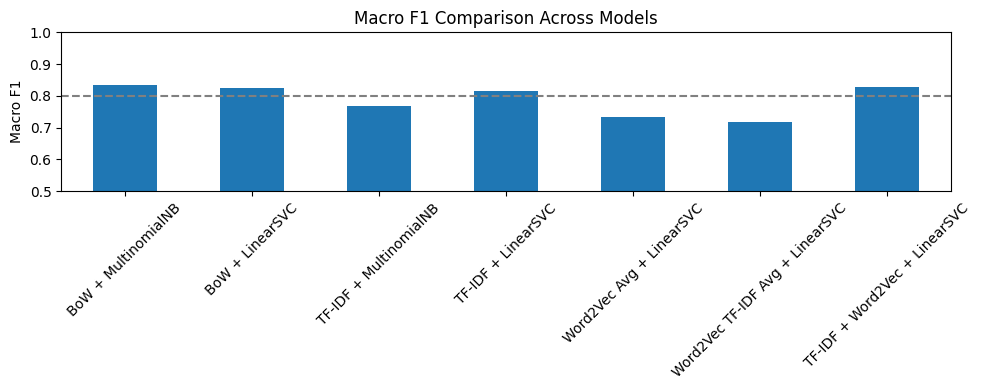

In [33]:
model_names = scores_df['Feature'] + ' + ' + scores_df['Model']
scores_df.set_index(model_names)['Macro F1'].plot(kind='bar', figsize=(10, 4), rot=45)
plt.axhline(0.8, color='gray', linestyle='--')
plt.title('Macro F1 Comparison Across Models')
plt.ylabel('Macro F1')
plt.ylim(0.5, 1.0)
plt.tight_layout()
plt.show()

### Đánh giá chi tiết mô hình tối ưu (Best Model Evaluation)

In [34]:
best_model = tuple(scores_df.loc[scores_df['Macro F1'].idxmax(), ['Feature', 'Model']])
print("Mô hình có Macro F1 cao nhất:", best_model)

Mô hình có Macro F1 cao nhất: ('BoW', 'MultinomialNB')


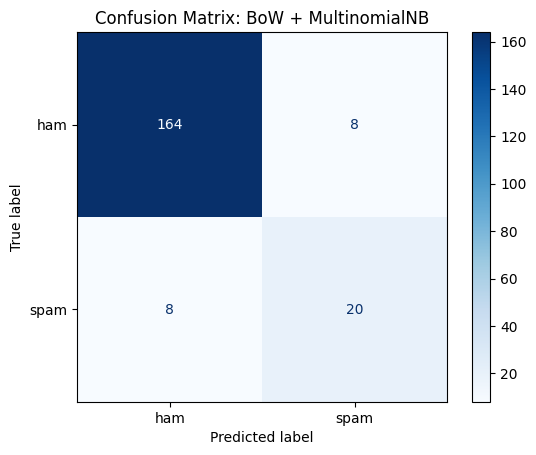

In [35]:
cm = confusion_matrix(test['label'], predictions[best_model], labels=['ham', 'spam'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['ham', 'spam'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix: ' + best_model[0] + ' + ' + best_model[1])
plt.show()

* **Báo cáo phân loại chi tiết (Classification Report)**:

In [36]:
print(classification_report(test['label'], predictions[best_model], digits=4))

              precision    recall  f1-score   support

         ham     0.9535    0.9535    0.9535       172
        spam     0.7143    0.7143    0.7143        28

    accuracy                         0.9200       200
   macro avg     0.8339    0.8339    0.8339       200
weighted avg     0.9200    0.9200    0.9200       200



### Phân tích lỗi (Error Analysis)
* Trích xuất và kiểm tra các trường hợp mô hình phân loại sai ($y_{true} \neq y_{pred}$) để xác định nguyên nhân gốc rễ (nhãn gán nhiễu, câu mập mờ, hoặc từ vựng mới phát sinh ngoài từ điển).

In [37]:
review = test[['content', 'label']].copy()
review['pred'] = predictions[best_model]
review[review['label'] != review['pred']].head(10)

,content,label,pred
18,b đưa sđt đây,spam,ham
876,Thời gian: 19:00–21:00 | Chủ nhật 20/09,spam,ham
877,Online | Miễn phí,spam,ham
208,"bạn ơi, kì này mình học hệ điều hành thầy Quân, bạn ib mình hỏi chút được không ?",ham,spam
871,"Mình muốn chia sẻ với mngworkshop “BẠN LÀ AI KHI BẠN LÊN TIẾNG?” khá hay, tập trung vào những điều tưởng nhỏ nhưng ảnh hưởng khá nhiều đến cách người khác cảm nhận về mình:",spam,ham
899,mình nha,ham,spam
178,có size XL ko c ơi,ham,spam
238,"""Everytime bạn nha """,spam,ham
684,mik cần tìm ng ở ghép ở yên xá,ham,spam
404,"mk có gtrinhf triết, giải tích, đại số 10k ạ",spam,ham


### Đánh giá trên tập kiểm thử cân bằng (Balanced Test Evaluation)
* Tiến hành lấy mẫu ngẫu nhiên (undersampling) lớp Ham để tạo tập test có tỷ lệ 1:1 với lớp Spam.

In [38]:
test_spam = test[test['label'] == 'spam']
test_ham = test[test['label'] == 'ham'].sample(n=len(test_spam), random_state=42)
test_balanced = pd.concat([test_spam, test_ham]).sample(frac=1.0, random_state=42)

idx_balanced = [test.index.get_loc(i) for i in test_balanced.index]
preds_bal = predictions[best_model][idx_balanced]

print(test_balanced['label'].value_counts())
print('Accuracy: ', round(accuracy_score(test_balanced['label'], preds_bal), 4))
print('Macro F1: ', round(f1_score(test_balanced['label'], preds_bal, average='macro'), 4))
print(classification_report(test_balanced['label'], preds_bal, digits=4))

label
spam    28
ham     28
Name: count, dtype: int64
Accuracy:  0.8036
Macro F1:  0.802
              precision    recall  f1-score   support

         ham     0.7576    0.8929    0.8197        28
        spam     0.8696    0.7143    0.7843        28

    accuracy                         0.8036        56
   macro avg     0.8136    0.8036    0.8020        56
weighted avg     0.8136    0.8036    0.8020        56



* Ma trận nhầm lẫn trên tập test cân bằng:

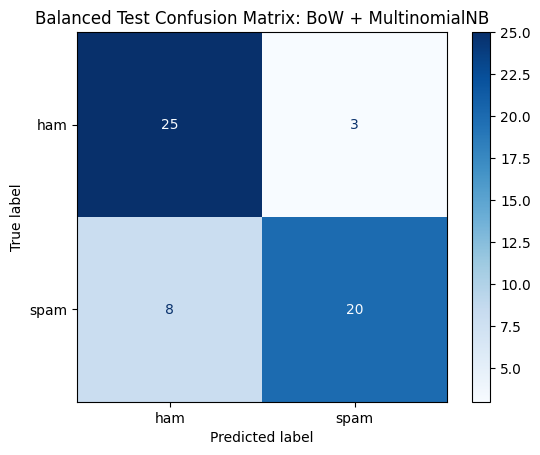

In [39]:
cm_bal = confusion_matrix(test_balanced['label'], preds_bal, labels=['ham', 'spam'])
disp_bal = ConfusionMatrixDisplay(confusion_matrix=cm_bal, display_labels=['ham', 'spam'])
disp_bal.plot(cmap='Blues')
plt.title('Balanced Test Confusion Matrix: ' + best_model[0] + ' + ' + best_model[1])
plt.show()